<b>DV Experiment 4: Interactive Dashboards with Filters and Slicers</b><br><br><b>Aim:</b> Build a retail executive dashboard linking orders with Dim_Customer.csv, featuring interactive Region slicer buttons and a Date range slider.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [2]:
data_dir = "datasets" if os.path.exists("datasets") else os.path.join("DV_Lab", "datasets")
out_dir = "outputs" if os.path.exists("outputs") else (os.path.join("DV_Lab", "outputs") if os.path.exists("DV_Lab") else "outputs")
os.makedirs(out_dir, exist_ok=True)

orders_df = pd.read_csv(os.path.join(data_dir, "superstore_sample.csv"))
cust_df = pd.read_csv(os.path.join(data_dir, "Dim_Customer.csv"))
df = orders_df.merge(cust_df, on="Customer_ID", how="left")
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Year_Month"] = df["Order_Date"].dt.to_period("M").astype(str)

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

In [3]:
profit_margin = total_profit / total_sales * 100.0
total_orders = df["Order_ID"].nunique()

print("Retail KPI Summary (Linked with Dim_Customer):")
print(f"Total Sales:   ${total_sales:,.2f}")
print(f"Total Profit:  ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders:  {total_orders}")

reg_summary = df.groupby("Region", as_index=False)[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
seg_summary = df.groupby("Segment", as_index=False)[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
sub_summary = df.groupby("Sub_Category", as_index=False)[["Sales", "Profit"]].sum().sort_values("Profit", ascending=True)
monthly_df = df.groupby("Year_Month", as_index=False)[["Sales", "Profit"]].sum().sort_values("Year_Month")

Retail KPI Summary (Linked with Dim_Customer):
Total Sales:   $553,903.20
Total Profit:  $76,496.65
Profit Margin: 13.81%
Total Orders:  340


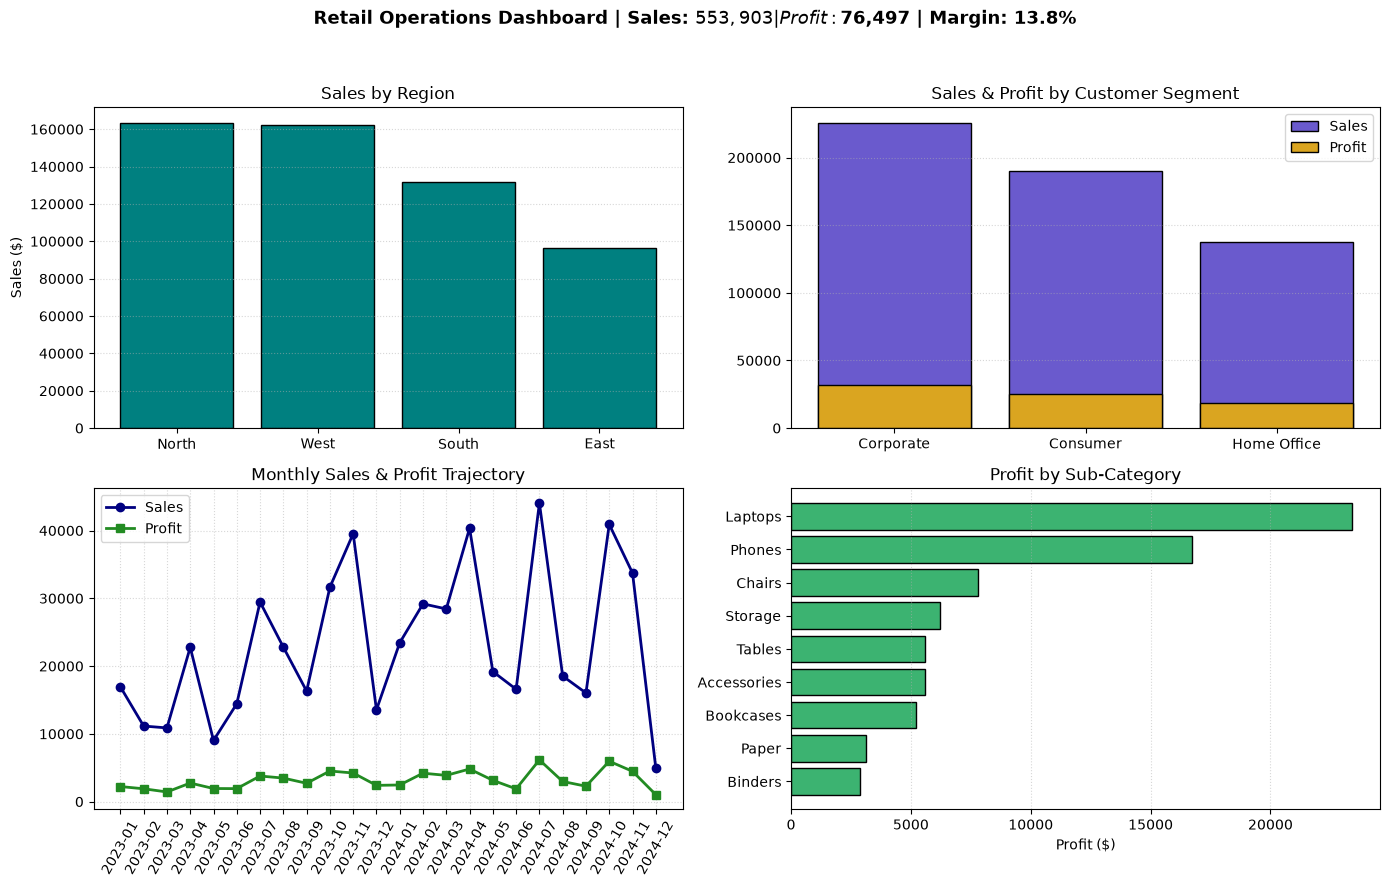

Interactive Dashboard saved to: outputs\DV_Exp4_Interactive_Dashboard.html


In [4]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(
    f"Retail Operations Dashboard | Sales: ${total_sales:,.0f} | Profit: ${total_profit:,.0f} | Margin: {profit_margin:.1f}%",
    fontsize=13,
    fontweight="bold",
)

ax[0, 0].bar(reg_summary["Region"], reg_summary["Sales"], color="teal", edgecolor="black")
ax[0, 0].set_title("Sales by Region")
ax[0, 0].set_ylabel("Sales ($)")
ax[0, 0].grid(True, axis="y", linestyle=":", alpha=0.5)

ax[0, 1].bar(seg_summary["Segment"], seg_summary["Sales"], color="slateblue", edgecolor="black", label="Sales")
ax[0, 1].bar(seg_summary["Segment"], seg_summary["Profit"], color="goldenrod", edgecolor="black", label="Profit")
ax[0, 1].set_title("Sales & Profit by Customer Segment")
ax[0, 1].legend()
ax[0, 1].grid(True, axis="y", linestyle=":", alpha=0.5)

ax[1, 0].plot(monthly_df["Year_Month"], monthly_df["Sales"], marker="o", color="navy", linewidth=2, label="Sales")
ax[1, 0].plot(monthly_df["Year_Month"], monthly_df["Profit"], marker="s", color="forestgreen", linewidth=2, label="Profit")
ax[1, 0].set_title("Monthly Sales & Profit Trajectory")
ax[1, 0].tick_params(axis="x", rotation=60)
ax[1, 0].legend()
ax[1, 0].grid(True, linestyle=":", alpha=0.5)

p_colors = ["mediumseagreen" if p >= 0 else "crimson" for p in sub_summary["Profit"]]
ax[1, 1].barh(sub_summary["Sub_Category"], sub_summary["Profit"], color=p_colors, edgecolor="black")
ax[1, 1].set_title("Profit by Sub-Category")
ax[1, 1].set_xlabel("Profit ($)")
ax[1, 1].grid(True, axis="x", linestyle=":", alpha=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

regions = ["All Regions"] + sorted(df["Region"].unique().tolist())

dash_fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Monthly Sales Trend (Date Range Slider)",
        "Sales by Category",
        "Profit by Sub-Category",
        "Sales by Customer Loyalty Tier",
    ),
    vertical_spacing=0.16,
    horizontal_spacing=0.10,
)

trace_meta = []
for reg in regions:
    sub_df = df if reg == "All Regions" else df[df["Region"] == reg]
    visible = reg == "All Regions"

    m_df = sub_df.groupby("Year_Month", as_index=False)["Sales"].sum().sort_values("Year_Month")
    c_df = sub_df.groupby("Category", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
    s_df = sub_df.groupby("Sub_Category", as_index=False)["Profit"].sum().sort_values("Profit")
    l_df = sub_df.groupby("Loyalty_Tier", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)

    dash_fig.add_trace(
        go.Scatter(x=m_df["Year_Month"], y=m_df["Sales"], mode="lines+markers", name=f"{reg} Trend", visible=visible, line=dict(color="navy", width=2.4)),
        row=1, col=1,
    )
    trace_meta.append(reg)

    dash_fig.add_trace(
        go.Bar(x=c_df["Category"], y=c_df["Sales"], name=f"{reg} Category", visible=visible, marker_color="darkorange"),
        row=1, col=2,
    )
    trace_meta.append(reg)

    dash_fig.add_trace(
        go.Bar(y=s_df["Sub_Category"], x=s_df["Profit"], orientation="h", name=f"{reg} Sub-Category", visible=visible, marker_color="seagreen"),
        row=2, col=1,
    )
    trace_meta.append(reg)

    dash_fig.add_trace(
        go.Bar(x=l_df["Loyalty_Tier"], y=l_df["Sales"], name=f"{reg} Loyalty", visible=visible, marker_color="slateblue"),
        row=2, col=2,
    )
    trace_meta.append(reg)

region_buttons = []
for reg in regions:
    vis_mask = [m == reg for m in trace_meta]
    reg_df = df if reg == "All Regions" else df[df["Region"] == reg]
    region_buttons.append(dict(
        label=reg,
        method="update",
        args=[
            {"visible": vis_mask},
            {"title": f"Interactive Retail Dashboard — {reg} | Sales: ${reg_df['Sales'].sum():,.0f} | Profit: ${reg_df['Profit'].sum():,.0f}"},
        ],
    ))

dash_fig.update_layout(
    height=780,
    width=1180,
    showlegend=False,
    title_text=f"Interactive Retail Dashboard — All Regions | Sales: ${total_sales:,.0f} | Profit: ${total_profit:,.0f}",
    updatemenus=[dict(
        type="buttons",
        direction="right",
        x=0.0,
        y=1.12,
        buttons=region_buttons,
        showactive=True,
    )],
)
dash_fig.update_xaxes(rangeslider_visible=True, row=1, col=1)

html_path = os.path.join(out_dir, "DV_Exp4_Interactive_Dashboard.html")
dash_fig.write_html(html_path, include_plotlyjs="cdn")
print("Interactive Dashboard saved to:", html_path)

<b>Observation:</b> Selecting Region slicers dynamically updates monthly trends, category totals, sub-category profit, and loyalty tier breakdowns.